In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np

In [2]:
dir_vf = r"./uwhv/CSV/VF_Data.csv"
df_vf = pd.read_csv(dir_vf)
display(df_vf.head())

dir_coord = r"./uwhv/CSV/Coord_242.csv"
df_coord = pd.read_csv(dir_coord)
display(df_coord.head())
# display(df_coord)

# dir_summary = r"./uwhv/CSV/Series_Summary.csv"
# df_summary = pd.read_csv(dir_summary)
# display(df_summary.head())

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63


,X,Y,Cluster,LocID
0,-9,21,1,1
1,-3,21,1,2
2,3,21,1,3
3,9,21,1,4
4,-15,15,1,5


In [3]:
print([i for i in df_vf.columns])

['PatID', 'Gender', 'Eye', 'FieldN', 'Age', 'Time_from_Baseline', 'MS', 'MS_Cluster1', 'MS_Cluster2', 'MS_Cluster3', 'MS_Cluster4', 'MS_Cluster5', 'MS_Cluster6', 'MTD', 'PSD', 'MTD_Cluster1', 'MTD_Cluster2', 'MTD_Cluster3', 'MTD_Cluster4', 'MTD_Cluster5', 'MTD_Cluster6', 'GH', 'Sens_1', 'Sens_2', 'Sens_3', 'Sens_4', 'Sens_5', 'Sens_6', 'Sens_7', 'Sens_8', 'Sens_9', 'Sens_10', 'Sens_11', 'Sens_12', 'Sens_13', 'Sens_14', 'Sens_15', 'Sens_16', 'Sens_17', 'Sens_18', 'Sens_19', 'Sens_20', 'Sens_21', 'Sens_22', 'Sens_23', 'Sens_24', 'Sens_25', 'Sens_26', 'Sens_27', 'Sens_28', 'Sens_29', 'Sens_30', 'Sens_31', 'Sens_32', 'Sens_33', 'Sens_34', 'Sens_35', 'Sens_36', 'Sens_37', 'Sens_38', 'Sens_39', 'Sens_40', 'Sens_41', 'Sens_42', 'Sens_43', 'Sens_44', 'Sens_45', 'Sens_46', 'Sens_47', 'Sens_48', 'Sens_49', 'Sens_50', 'Sens_51', 'Sens_52', 'Sens_53', 'Sens_54', 'TD_1', 'TD_2', 'TD_3', 'TD_4', 'TD_5', 'TD_6', 'TD_7', 'TD_8', 'TD_9', 'TD_10', 'TD_11', 'TD_12', 'TD_13', 'TD_14', 'TD_15', 'TD_16', 'T

PatID: 患者識別番号

Gender: 患者の性別

Eye: laterality (Right/Left)横方向(右/左)

FieldN: sequential test number for each eye (time ordered)

Age: patient age at each test (years)

Time_from_Baseline: calculated as Age (at test N) - Age (at test 1)

MS: Mean Sensitivity

MS_Cluster1 to 6: MS for each cluster

MTD: Mean Total Deviation

PSD: Pattern Standard Deviation

MTD_Cluster1 to 6: MTD for each cluster

GH: General Height (7th highest TD value)

Sens_1 to 54: Sensitivity values for each location

TD_1 to 54: Total Deviation values for each location (missing for blind spot locations)

PD_1 to 54: Pattern Deviation values for each location (missing for blind spot locations)

In [4]:
print(len(df_vf["PatID"].unique()))
print(len(df_vf["Gender"].unique()))
print(len(df_vf["Eye"].unique()))
print(len(df_vf["PatID"].unique()))

3871
4
2
3871


In [5]:
df_vf["Gender"].unique()

<ArrowStringArray>
['F', 'M', nan, 'O']
Length: 4, dtype: str

In [6]:
import itertools

In [7]:
l_keys = ["Gender", "Eye"]
for i_key in l_keys:
    print("===", i_key, "===")
    for i_label in df_vf[i_key].unique():
        print(i_label, len(df_vf[df_vf[i_key]==i_label]))

print("====matrix====")
for i_gen, i_eye in itertools.product(df_vf["Gender"].unique(), df_vf["Eye"].unique()):

    print(i_gen, i_eye, len(df_vf[(df_vf["Gender"]==i_gen)&(df_vf["Eye"]==i_eye)]))

=== Gender ===
F 12815
M 10582
nan 0
O 17
=== Eye ===
Right 14433
Left 14510
====matrix====
F Right 6381
F Left 6434
M Right 5290
M Left 5292
nan Right 0
nan Left 0
O Right 8
O Left 9


数が多く右目の`F Right 6381`条件でまずは確かめる

In [8]:
display(df_vf[(df_vf["Gender"]=="F")&(df_vf["Eye"]=="Right")&(df_vf["PatID"]==647)])

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63
5,647,F,Right,6,62.5243,9.7276,28.814615,25.96875,28.509231,31.263333,...,-0.13,-0.30,-0.70,-1.43,-1.39,-4.04,-0.48,-0.29,-2.78,-2.02
6,647,F,Right,7,63.7892,10.9925,27.219038,22.46375,26.590769,30.396667,...,-0.51,0.82,-1.06,-2.96,-1.64,-1.94,0.00,-1.35,-0.10,-0.62
7,647,F,Right,8,64.2491,11.4524,28.433077,25.63250,28.636154,31.310000,...,-2.53,-3.12,-0.27,-1.90,0.49,0.53,-3.08,-2.30,-0.42,-3.38
8,647,F,Right,9,65.7440,12.9473,28.275385,25.27500,28.032308,30.880000,...,-2.67,-0.38,0.61,0.07,-1.39,-4.09,1.09,-2.52,-3.33,-0.47
9,647,F,Right,10,66.8063,14.0096,28.166923,23.00500,26.757692,33.136667,...,-2.28,-3.27,1.18,2.13,0.00,-3.26,-0.13,-3.32,-2.03,-4.01


両眼検査している人は2データ分積み重ねている。データは奇数件なので後々影響が出そう。

`display(df_vf[(df_vf["Gender"]=="F")&(df_vf["PatID"]==647)])`

In [9]:
# 両眼が同じ試験回数
l_num_eyes = []
for i_id in df_vf["PatID"].unique():
    df_slice = df_vf[df_vf["PatID"]==i_id]
    l_num_eyes.append((len(df_slice[df_slice["Eye"]=="Right"]), len(df_slice[df_slice["Eye"]=="Left"]), df_slice["PatID"].iloc[0]))

l_num_eyes_same = [i for i in l_num_eyes if i[0]==i[1]]

print(len(l_num_eyes_same))
print(len(l_num_eyes_same)/len(l_num_eyes))

3083
0.7964350297080858


In [10]:
# 偏っているデータのうち、トレーニングに使えるもの。両目とも4件以上なら。
l_num_eyes_not_same = [i for i in l_num_eyes if i[0]!=i[1]]
print(l_num_eyes_not_same[0])
l_num_eyes_not_same_over4 = [i for i in l_num_eyes_not_same if (i[0]>3)and(i[1]>3)]
print(len(l_num_eyes_not_same))
print(len(l_num_eyes_not_same_over4))
print(l_num_eyes_not_same_over4[0])

df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
bool_same_place = df_slice_eye_not_same["FieldN"].duplicated(keep=False)
display(df_slice_eye_not_same[bool_same_place])

(2, 0, np.int64(1304))
788
303
(5, 4, np.int64(3597))


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


## データの確認

基本は`Sens_xx`のデータを用いる

In [11]:
df_vf.columns

Index(['PatID', 'Gender', 'Eye', 'FieldN', 'Age', 'Time_from_Baseline', 'MS',
       'MS_Cluster1', 'MS_Cluster2', 'MS_Cluster3',
       ...
       'PD_45', 'PD_46', 'PD_47', 'PD_48', 'PD_49', 'PD_50', 'PD_51', 'PD_52',
       'PD_53', 'PD_54'],
      dtype='str', length=184)

In [12]:
l_col_sens = [i for i in df_vf.columns if "Sens_" in i]
# l_col_sens

In [13]:
df_coord

,X,Y,Cluster,LocID
0,-9,21,1,1
1,-3,21,1,2
2,3,21,1,3
3,9,21,1,4
4,-15,15,1,5
5,-9,15,2,6
6,-3,15,2,7
7,3,15,2,8
8,9,15,1,9
9,15,15,1,10


In [14]:
l_col_td = [i for i in df_vf.columns if "TD_" in i]
(df_vf[l_col_td]==100).sum().max()

np.int64(0)

In [15]:
type(data_vf_slice)

NameError: name 'data_vf_slice' is not defined

In [ ]:
df_vf[l_col_sens]

,Sens_1,Sens_2,Sens_3,Sens_4,Sens_5,Sens_6,Sens_7,Sens_8,Sens_9,Sens_10,...,Sens_45,Sens_46,Sens_47,Sens_48,Sens_49,Sens_50,Sens_51,Sens_52,Sens_53,Sens_54
0,26.34,23.73,22.84,24.19,26.25,27.22,25.67,26.18,27.01,26.24,...,26.88,29.43,29.82,28.64,29.81,28.24,28.88,27.30,26.82,28.18
1,27.97,26.32,28.60,26.22,28.15,30.42,27.30,29.85,28.97,26.01,...,31.05,31.45,31.24,31.21,30.44,30.86,26.07,29.18,31.64,31.86
2,22.52,21.09,23.05,23.39,30.01,30.41,28.23,28.12,28.54,27.19,...,31.11,33.74,30.56,32.62,31.38,29.24,30.04,26.92,29.96,27.10
3,23.07,20.61,21.03,20.71,29.04,27.68,27.84,26.33,25.50,22.30,...,27.55,29.39,31.08,28.79,29.69,27.30,26.46,23.49,27.99,27.35
4,24.83,22.88,26.14,22.95,25.07,27.33,26.46,26.39,25.75,24.18,...,28.19,29.09,27.40,27.82,26.79,26.37,26.92,28.68,28.04,26.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28938,21.56,25.15,26.69,25.96,22.65,22.94,25.67,26.98,26.63,24.57,...,29.71,26.58,26.24,27.36,29.60,29.20,28.78,26.51,28.68,27.39
28939,27.05,28.78,28.58,20.72,22.66,28.18,30.03,29.34,28.29,27.04,...,29.85,30.71,28.34,31.73,30.80,31.86,25.73,28.05,30.70,28.24
28940,24.31,25.05,21.18,19.61,25.27,26.91,26.69,23.08,22.36,25.97,...,29.12,29.42,30.01,30.78,30.09,27.70,29.74,26.02,27.40,28.22
28941,27.15,28.71,26.94,25.93,28.09,29.09,30.05,28.06,25.86,26.40,...,25.15,26.05,22.07,25.15,28.12,28.26,26.69,26.33,27.21,29.84


PatID         647
Gender          F
Eye         Right
FieldN          1
Age       52.7967
           ...   
PD_50       -1.06
PD_51        0.75
PD_52       -1.33
PD_53       -2.02
PD_54       -0.61
Name: 0, Length: 184, dtype: object

/tmp/ipykernel_45894/1197326988.py:31: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  sc = ax.scatter(


[]

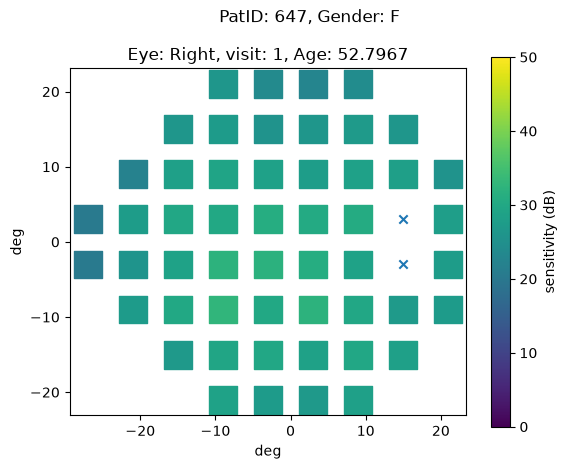

In [ ]:
df_data_slice = df_vf.iloc[0]
data_vf_slice = df_data_slice[l_col_sens]
display(df_data_slice)
# display(data_vf_slice)
# display(df_coord)

sens_max = df_vf[l_col_sens].max().max()
sens_min = df_vf[l_col_sens].min().min()

df_not_blind = df_coord["Cluster"]!=0
df_blind = df_coord["Cluster"]==0

# print(df_blind.shape)
# print(df_coord["X"].shape)
# print(df_coord["Y"].shape)
# print(data_vf_slice.shape)

# for i_loc in l_col_sens:
#     print(data_vf_slice[i_loc])
#     i_loc_vf = df_coord["LocID"]==int(i_loc.replace("Sens_",""))
#     display(df_coord[i_loc_vf])
#     break
# 'PatID', 'Gender', 'Eye', 'FieldN', 'Age'
fig = plt.figure()

s_suptitle = f"PatID: {df_data_slice["PatID"]}, Gender: {df_data_slice["Gender"]}"
fig.suptitle(s_suptitle)

ax = fig.add_subplot(111, xlabel="deg", ylabel='deg')
ax.set_aspect("equal")
sc = ax.scatter(
    df_coord["X"][df_not_blind], 
    df_coord["Y"][df_not_blind], 
    c=data_vf_slice.to_numpy()[df_not_blind], # Booleanマスクのindexが異なる場合は.to_numpy() # chatgpt
    s=400, 
    vmax=sens_max, vmin=sens_min, marker=",")#, linewidths=10)
fig.colorbar(sc, ax=ax).set_label("sensitivity (dB)")

ax.scatter(df_coord["X"][df_blind], df_coord["Y"][df_blind], marker="x")
s_ax_title = f"Eye: {df_data_slice["Eye"]}, visit: {df_data_slice["FieldN"]}, Age: {df_data_slice["Age"]}"
ax.set_title(s_ax_title)

plt.plot()

Sens_1     26.34
Sens_2     23.73
Sens_3     22.84
Sens_4     24.19
Sens_5     26.25
Sens_6     27.22
Sens_7     25.67
Sens_8     26.18
Sens_9     27.01
Sens_10    26.24
Sens_11     22.2
Sens_12    28.17
Sens_13     29.2
Sens_14    28.44
Sens_15    27.58
Sens_16    28.51
Sens_17    28.02
Sens_18    25.68
Sens_19     20.4
Sens_20    27.41
Sens_21    29.73
Sens_22    30.02
Sens_23    30.93
Sens_24    30.36
Sens_25    30.64
Sens_26       21
Sens_27    27.89
Sens_28    20.45
Sens_29    25.88
Sens_30     28.9
Sens_31    32.17
Sens_32    31.89
Sens_33    30.91
Sens_34     28.8
Sens_35      0.0
Sens_36    27.43
Sens_37    27.16
Sens_38    29.98
Sens_39    32.74
Sens_40    29.95
Sens_41    32.07
Sens_42    29.84
Sens_43    26.99
Sens_44     27.3
Sens_45    26.88
Sens_46    29.43
Sens_47    29.82
Sens_48    28.64
Sens_49    29.81
Sens_50    28.24
Sens_51    28.88
Sens_52     27.3
Sens_53    26.82
Sens_54    28.18
Name: 0, dtype: object

/tmp/ipykernel_45894/2195345513.py:33: UserWarning: The pixel maker ',' is not supported on scatter(); using a finite-sized square instead, which is not necessarily 1 pixel in size. Use the square marker 's' instead to suppress this warning.
  sc = axes[0,0].scatter(


[]

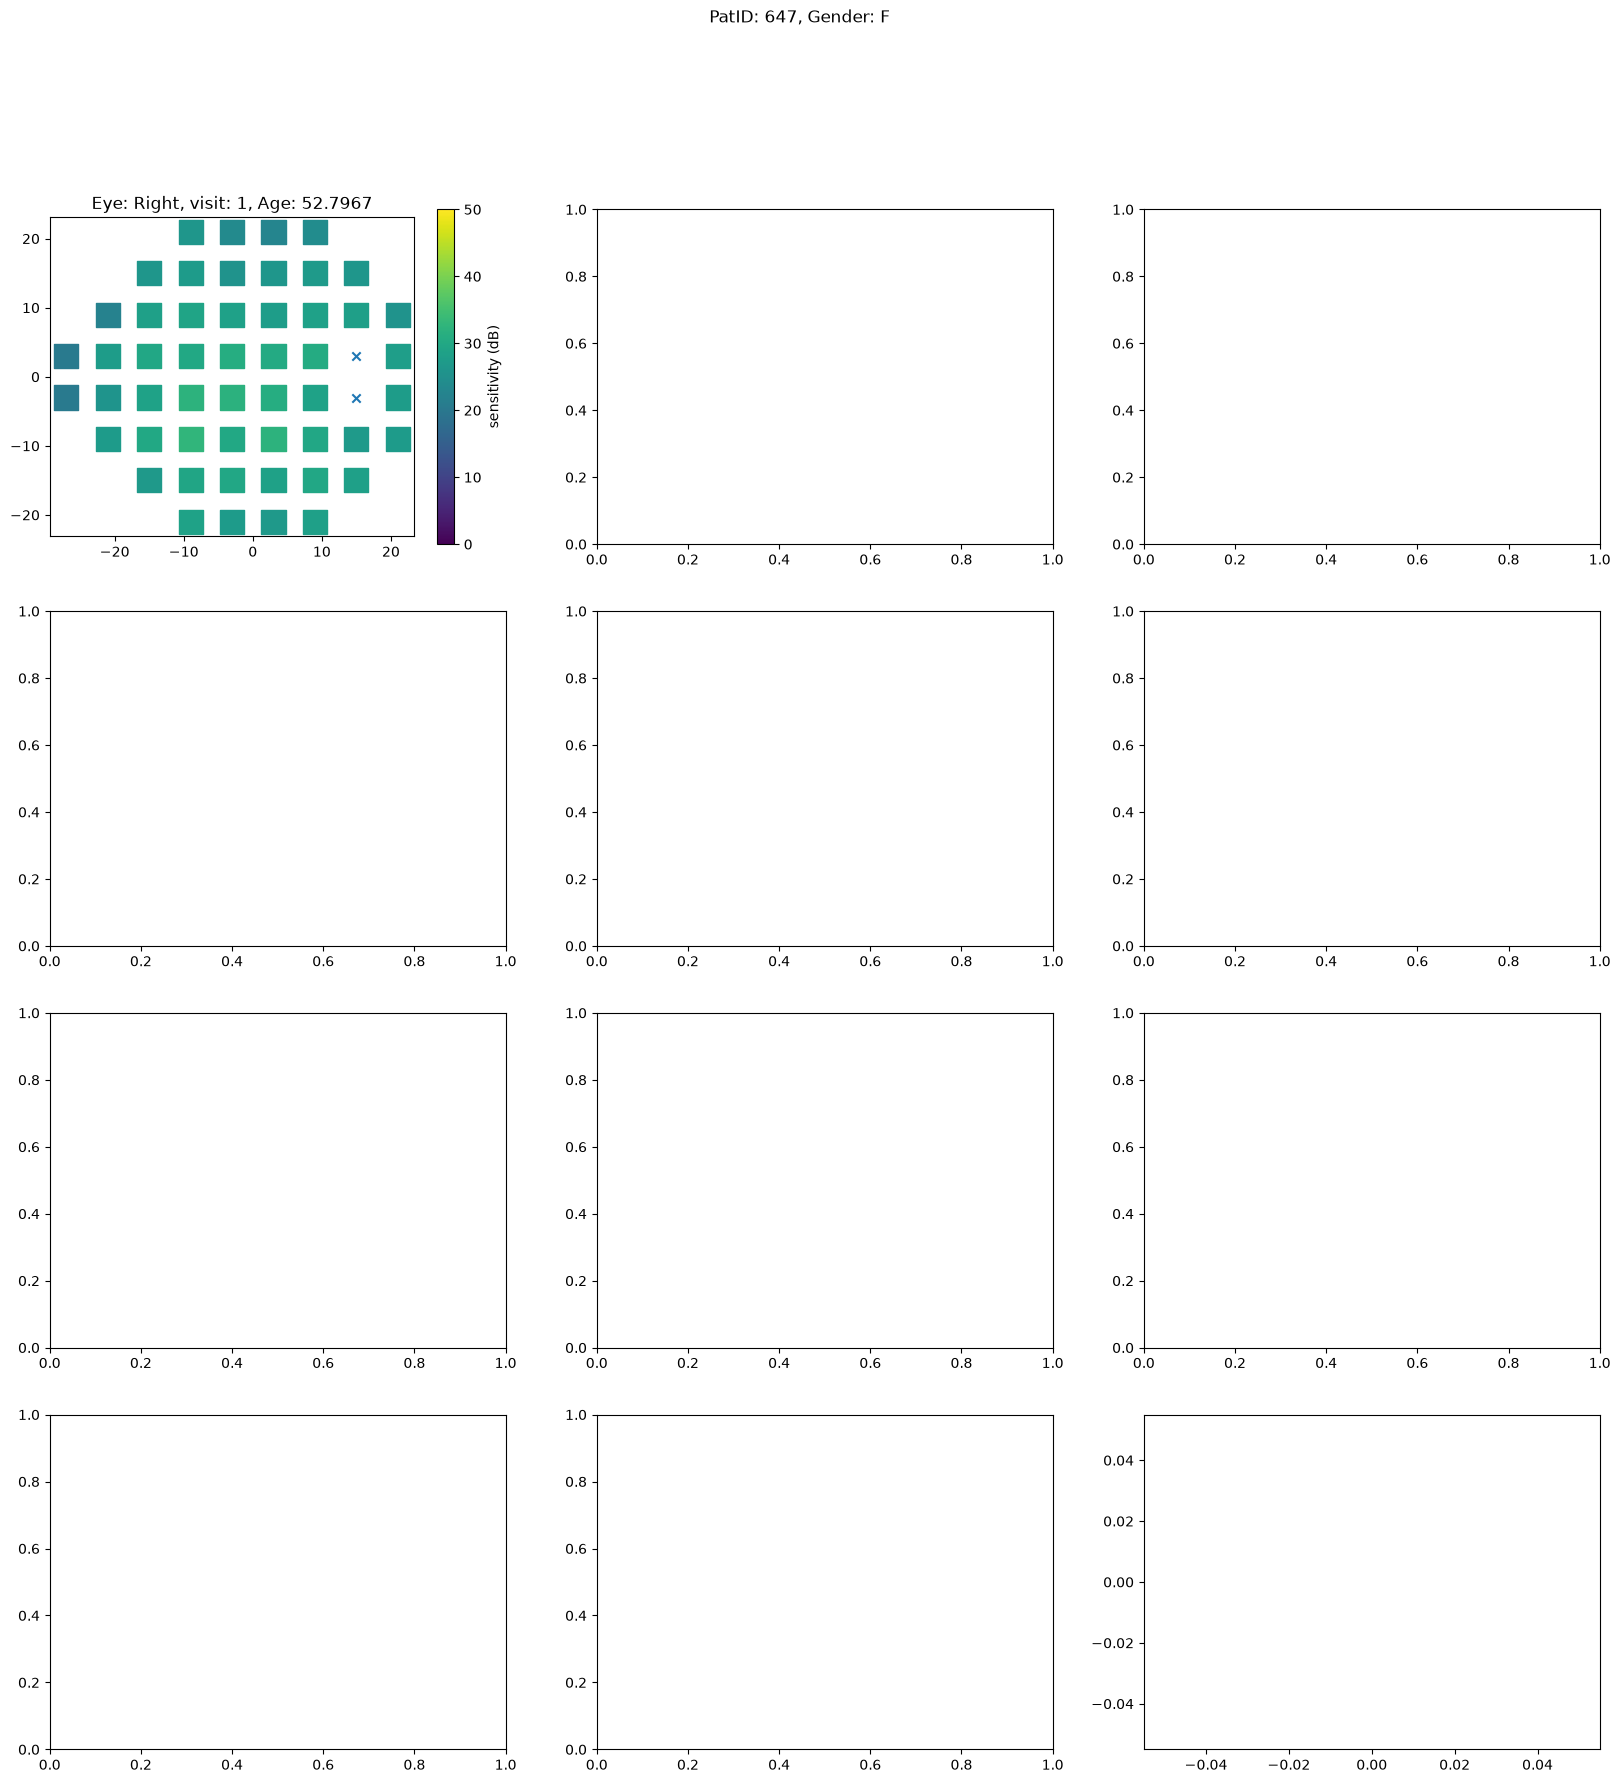

In [ ]:
df_data_slice = df_vf.iloc[0]
data_vf_slice = df_data_slice[l_col_sens]
# display(df_data_slice)
# display(data_vf_slice)
# display(df_coord)

sens_max = df_vf[l_col_sens].max().max()
sens_min = df_vf[l_col_sens].min().min()

df_not_blind = df_coord["Cluster"]!=0
df_blind = df_coord["Cluster"]==0

# print(df_blind.shape)
# print(df_coord["X"].shape)
# print(df_coord["Y"].shape)
# print(data_vf_slice.shape)

# for i_loc in l_col_sens:
#     print(data_vf_slice[i_loc])
#     i_loc_vf = df_coord["LocID"]==int(i_loc.replace("Sens_",""))
#     display(df_coord[i_loc_vf])
#     break
# 'PatID', 'Gender', 'Eye', 'FieldN', 'Age'
fig = plt.figure(figsize=(20,20))

s_suptitle = f"PatID: {df_data_slice["PatID"]}, Gender: {df_data_slice["Gender"]}"
fig.suptitle(s_suptitle)

axes = fig.subplots(4, 3)

# axes[0] = fig.add_subplot(111, xlabel="deg", ylabel='deg')
axes[0,0].set_aspect("equal")
sc = axes[0,0].scatter(
    df_coord["X"][df_not_blind], 
    df_coord["Y"][df_not_blind], 
    c=data_vf_slice.to_numpy()[df_not_blind], # Booleanマスクのindexが異なる場合は.to_numpy() # chatgpt
    s=300, 
    vmax=sens_max, vmin=sens_min, marker=",")#, linewidths=10)
fig.colorbar(sc, ax=axes[0,0]).set_label("sensitivity (dB)")

axes[0,0].scatter(df_coord["X"][df_blind], df_coord["Y"][df_blind], marker="x")
s_ax_title = f"Eye: {df_data_slice["Eye"]}, visit: {df_data_slice["FieldN"]}, Age: {df_data_slice["Age"]}"
axes[0,0].set_title(s_ax_title)

plt.plot()

In [ ]:
df_not_blind = df_coord["Cluster"]!=0
df_col_sens_not_blind = np.array(l_col_sens)[df_not_blind]
df_vf.groupby(["PatID", "Eye", "Age"])[df_col_sens_not_blind].mean()

Sens_1  Sens_2  Sens_3  Sens_4  Sens_5  Sens_6  Sens_7  \
PatID Eye   Age                                                               
1     Left  78.9432    0.00   17.28    0.00    0.00   18.56   23.22   18.50   
            84.3012   10.91    0.00    8.17    0.00   10.38   17.45   19.54   
            85.7577   11.39    9.22    0.00    9.84   21.63   22.58   21.49   
            86.8884    7.36    0.46    2.58    0.00   14.87   20.58   13.83   
            87.9425    9.16   10.33    0.00   16.29   18.53   21.84   22.88   
...                     ...     ...     ...     ...     ...     ...     ...   
8393  Right 75.2799   28.49   26.80   27.80   26.52   23.94   25.83   27.17   
            76.2765   26.12   26.16   24.92   24.45   27.92   27.49   28.38   
            77.2731   25.38   27.89   28.88   28.11   29.23   30.74   29.27   
8547  Left  54.8775   25.73   21.14   24.93   26.83   25.42   28.66   26.28   
            55.3758   26.09   25.40   27.39   17.85   31.62   27.37   26.94   

                     Sens_8  Sens_9  Sens_10  ...  Sens_45  Sens_46  Sens_47  \
PatID Eye   Age                               ...                              
1     Left  78.9432   18.18   24.62    20.47  ...    26.46    24.62    26.55   
            84.3012   19.12   20.85    24.91  ...    28.72    26.01    26.97   
            85.7577    9.78   22.63    18.32  ...    18.58    24.46    24.09   
            86.8884   14.79   18.03    15.04  ...    21.03    22.04    22.37   
            87.9425   17.60   23.32    20.91  ...    18.54    24.94    23.33   
...                     ...     ...      ...  ...      ...      ...      ...   
8393  Right 75.2799   26.51   26.08    27.32  ...    26.68    27.82    25.72   
            76.2765   24.16   25.49    24.80  ...    28.94    28.78    26.12   
            77.2731   31.58   30.84    28.20  ...    28.92    29.04    27.14   
8547  Left  54.8775   24.97   27.30    28.81  ...    21.47    24.73    26.49   
            55.3758   28.06   25.00    24.63  ...    26.79    26.43    26.43   

                     Sens_48  Sens_49  Sens_50  Sens_51  Sens_52  Sens_53  \
PatID Eye   Age                                                             
1     Left  78.9432    25.64    27.94    25.88    19.83    21.34    24.01   
            84.3012    28.99    28.48    27.37    22.36    27.00    26.60   
            85.7577    23.89    26.36    25.56    20.16    22.24    22.99   
            86.8884    21.79    24.84    21.66    20.71    16.94    17.06   
            87.9425    24.89    25.05    24.59    19.96    18.49    22.97   
...                      ...      ...      ...      ...      ...      ...   
8393  Right 75.2799    24.80    27.85    28.93    24.67    22.60    29.68   
            76.2765    27.67    27.74    22.37    27.93    27.11    26.55   
            77.2731    24.09    27.55    24.92    28.71    22.84    17.73   
8547  Left  54.8775    28.36    29.87    31.77    26.61    25.67    28.01   
            55.3758    28.69    30.03    31.80    24.97    17.28    23.82   

                     Sens_54  
PatID Eye   Age               
1     Left  78.9432    25.91  
            84.3012    24.33  
            85.7577    19.08  
            86.8884    24.69  
            87.9425    21.99  
...                      ...  
8393  Right 75.2799    27.78  
            76.2765    25.52  
            77.2731    21.56  
8547  Left  54.8775    25.99  
            55.3758    28.96  

[28943 rows x 52 columns]

In [ ]:
df_vf.groupby(["PatID", "Eye",])[df_vf["Age"].duplicated(keep=False)]

KeyError: 'Columns not found: False, True'

In [17]:
df_vf[df_vf["Age"].duplicated(keep=False)]

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,647,F,Right,1,52.7967,0.0000,27.832885,25.57750,26.979231,30.588333,...,-1.92,-0.36,-0.44,-1.52,-0.03,-1.06,0.75,-1.33,-2.02,-0.61
1,647,F,Right,2,53.8234,1.0267,30.131346,27.76000,29.911538,33.263333,...,-0.54,-1.13,-1.81,-1.74,-2.19,-1.23,-4.85,-2.24,0.00,0.28
2,647,F,Right,3,54.8857,2.0890,29.454808,25.47500,29.826154,32.488333,...,-0.07,1.56,-2.09,0.07,-0.84,-2.45,-0.48,-4.10,-1.28,-4.07
3,647,F,Right,4,57.7331,4.9363,27.947885,23.75625,28.658462,31.431667,...,-2.57,-1.74,-0.52,-2.70,-1.48,-3.32,-3.00,-6.49,-2.19,-2.76
4,647,F,Right,5,58.7680,5.9713,27.644038,24.90250,28.104615,30.105000,...,-0.80,-0.93,-3.08,-2.55,-3.26,-3.13,-1.42,-0.18,-1.02,-2.63
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28938,7324,F,Left,2,65.6537,0.2163,27.471923,25.32125,25.657692,30.785000,...,0.30,-3.89,-4.68,-3.45,-0.88,-0.72,0.00,-2.81,-0.83,-2.02
28939,6859,M,Right,1,79.4114,0.0000,23.916346,26.37000,15.611538,15.225000,...,-0.43,-0.71,-3.52,0.00,-0.60,1.05,-3.96,-2.23,0.25,-2.06
28940,6859,M,Right,2,80.6598,1.2485,23.475192,23.74500,13.599231,22.355000,...,0.00,-0.85,-0.70,0.20,-0.16,-1.95,1.20,-3.11,-1.91,-0.93
28941,1142,NaN,Left,1,67.3155,0.0000,27.896923,26.95250,29.080000,30.493333,...,-4.77,-4.94,-9.38,-6.18,-2.88,-2.18,-2.61,-3.51,-2.83,-0.09


In [18]:
df_vf[df_vf["PatID"]==647]["Age"].duplicated(keep=False)

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
14    True
15    True
16    True
17    True
18    True
19    True
20    True
21    True
Name: Age, dtype: bool

In [19]:
import os
from tqdm import tqdm

In [20]:
dir_save = "./imgs"
os.makedirs(dir_save, exist_ok=True)

In [21]:
l_num_eyes_not_same = [i for i in l_num_eyes if i[0]!=i[1]]
print(l_num_eyes_not_same[0])
l_num_eyes_not_same_over4 = [i for i in l_num_eyes_not_same if (i[0]>3)and(i[1]>3)]
print(len(l_num_eyes_not_same))
print(len(l_num_eyes_not_same_over4))
print(l_num_eyes_not_same_over4[0])

df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
bool_same_place = df_slice_eye_not_same["FieldN"].duplicated(keep=False)
display(df_slice_eye_not_same[bool_same_place])


l_num_eyes_over4 = [i for i in l_num_eyes if (i[0]>3)and(i[1]>3)and(i[0]!=i[1])]

(2, 0, np.int64(1304))
788
303
(5, 4, np.int64(3597))


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


In [ ]:
df_slice_eye_not_same = df_vf[df_vf["PatID"]==l_num_eyes_not_same_over4[0][2]]
display(df_slice_eye_not_same)

# 多分、両眼の記録として処理するならこれがいい
df_filtered = df_slice_eye_not_same[
    df_slice_eye_not_same.groupby(["PatID", "Age"])["Eye"].transform("nunique") == 2
]
display(df_filtered)

# bool_same_place = df_slice_eye_not_same["Age"].duplicated(keep=False)
# display(df_slice_eye_not_same[bool_same_place])

,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
222,3597,F,Right,4,68.8131,4.2355,24.935192,22.06750,26.676923,29.010000,...,-10.43,-2.01,-3.21,-3.48,-3.68,-7.73,-13.12,-10.39,-6.99,-5.04
223,3597,F,Right,5,69.0705,4.4928,23.261154,19.49500,25.153077,29.443333,...,-12.85,-4.80,-4.62,-4.81,-1.92,-4.24,-7.24,-20.70,-5.75,-6.74
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
223,3597,F,Right,5,69.0705,4.4928,23.261154,19.49500,25.153077,29.443333,...,-12.85,-4.80,-4.62,-4.81,-1.92,-4.24,-7.24,-20.70,-5.75,-6.74
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
219,3597,F,Right,1,64.5777,0.0000,28.653654,25.19750,28.372308,32.520000,...,-3.18,-3.67,-2.17,-1.14,-3.80,-1.15,-3.56,-3.01,-3.00,-3.86
220,3597,F,Right,2,65.0760,0.4983,30.100192,28.16500,30.953846,32.426667,...,-4.40,-3.63,-2.78,-3.48,-3.61,-7.42,-2.67,-5.41,-6.88,-9.36
221,3597,F,Right,3,68.7556,4.1780,18.779038,12.91125,18.923077,28.381667,...,-11.94,-9.58,-9.64,-3.39,-6.50,-8.20,-16.90,-12.58,-4.05,-8.75
223,3597,F,Right,5,69.0705,4.4928,23.261154,19.49500,25.153077,29.443333,...,-12.85,-4.80,-4.62,-4.81,-1.92,-4.24,-7.24,-20.70,-5.75,-6.74
224,3597,F,Left,1,64.5777,0.0000,30.101923,25.86875,28.997692,33.413333,...,-1.33,-0.12,-1.62,0.54,-0.20,-0.14,-1.82,-4.45,-1.00,-0.05
225,3597,F,Left,2,65.0760,0.4983,29.929231,28.25625,29.280000,31.700000,...,4.36,-1.21,-1.37,-1.50,-0.58,-0.64,-5.13,-1.49,-3.80,-5.19
226,3597,F,Left,3,68.7556,4.1780,22.125000,18.99375,21.947692,25.798333,...,-7.33,-3.42,-2.68,-1.68,-2.33,-3.03,-2.16,-2.73,-0.61,0.73
227,3597,F,Left,4,69.0705,4.4928,27.690000,22.80625,27.481538,30.626667,...,-2.52,-0.41,-2.05,-1.61,-3.57,-1.98,-3.57,-3.50,-3.98,-2.73


In [22]:
for i_id in df_vf["PatID"].unique():
    
    df_slice = df_vf[df_vf["PatID"]==i_id]
    
    

  0%|          | 3/1409 [00:02<22:21,  1.05it/s]


KeyboardInterrupt: 

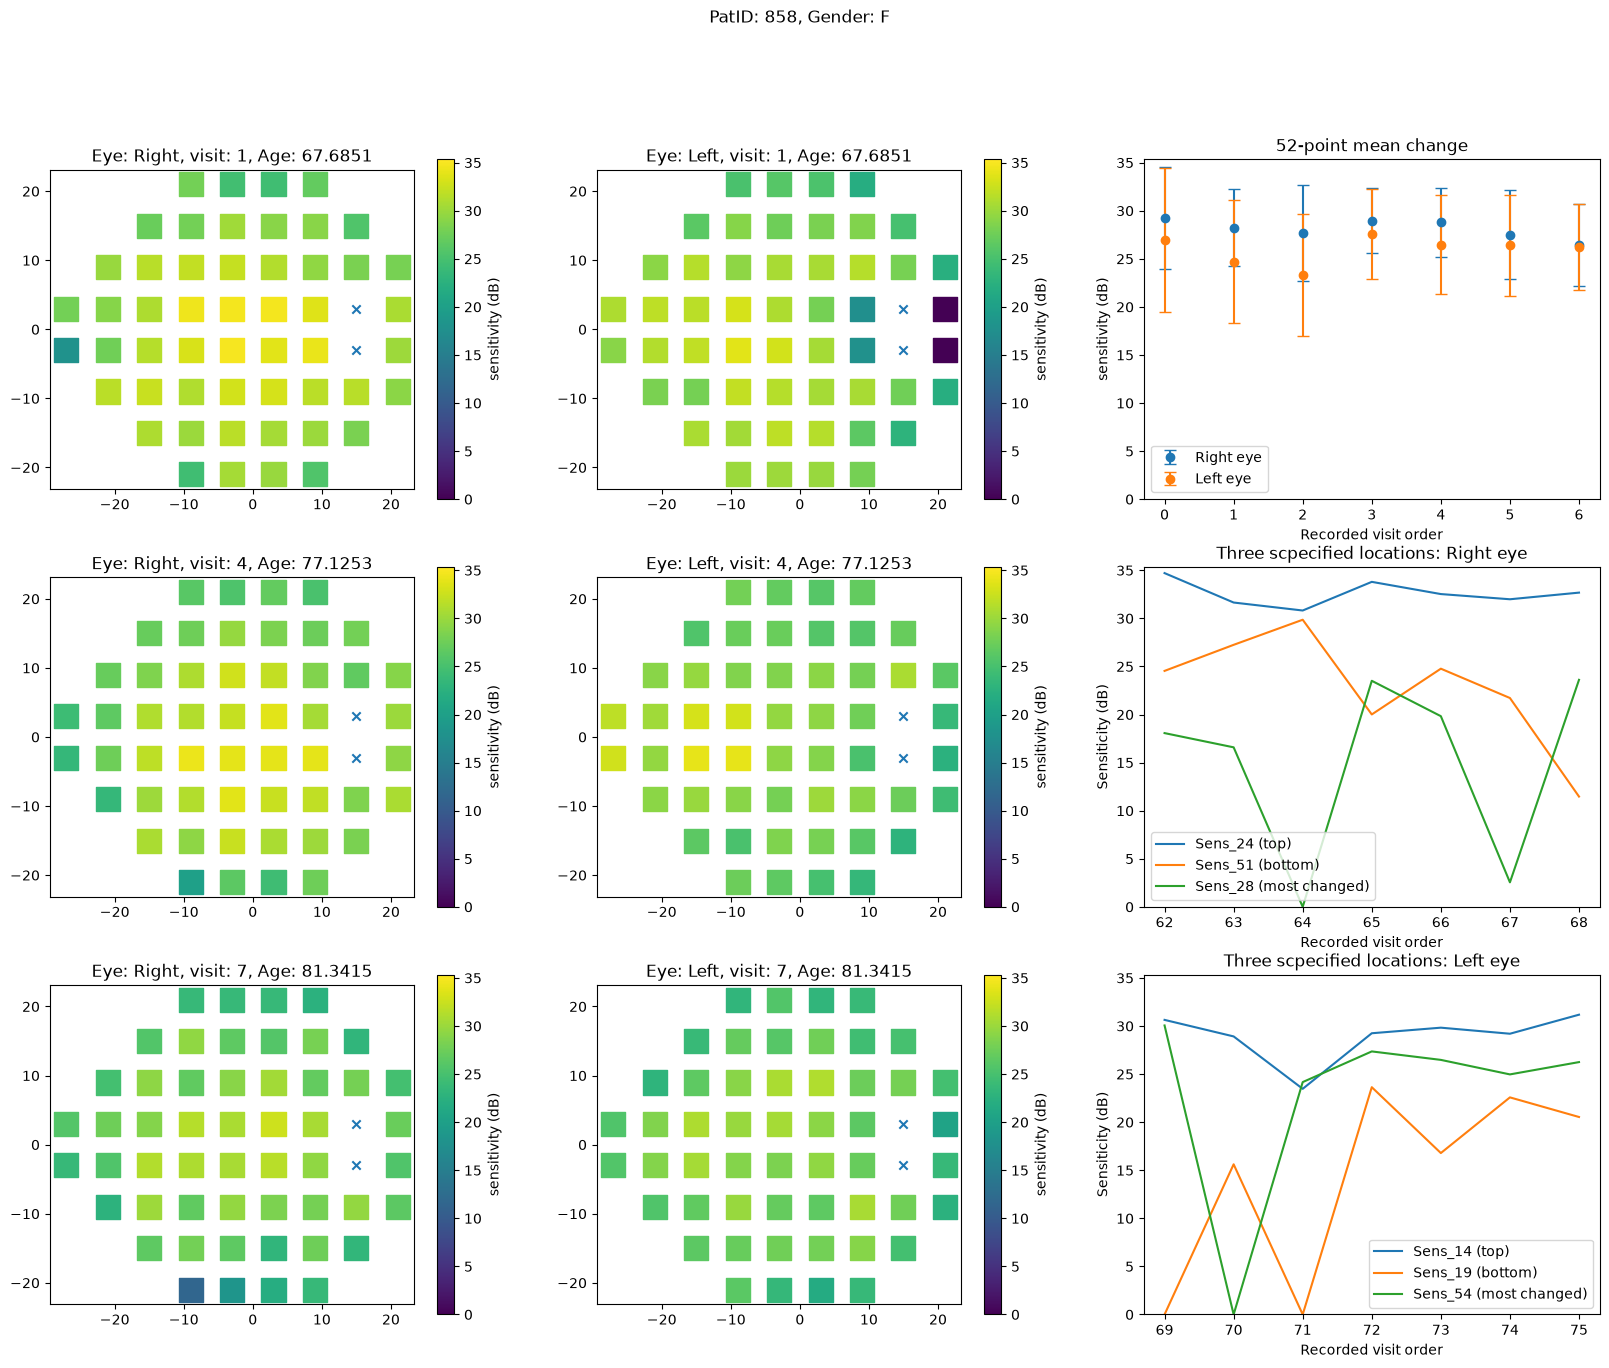

In [ ]:
# 患者画像概要の保存
df_vf["PatID"].unique()
l_num_eyes_over4 = [i for i in l_num_eyes if (i[0]>3)and(i[1]>3)]
for i_eyes_over4 in tqdm(l_num_eyes_over4):
    i_id = int(i_eyes_over4[2])
    df_slice = df_vf[df_vf["PatID"]==i_id]

    bool_same_visits = df_slice["FieldN"].duplicated(keep=False)
    df_slice_same_visits  = df_slice[bool_same_visits].copy()
    # display(df_slice_same_visits)
    l_view_visits = [1, round(df_slice_same_visits["FieldN"].mean()), int(df_slice_same_visits["FieldN"].max())]
    # print(l_view_visits)
    
    # df_data_slice = df_vf.iloc[0]
    
    data_vf_slice = df_slice_same_visits[l_col_sens]
    # display(df_data_slice)
    # display(data_vf_slice)
    # display(df_coord)

    sens_max = df_slice_same_visits[l_col_sens].max().max()
    sens_min = df_slice_same_visits[l_col_sens].min().min()

    df_not_blind = df_coord["Cluster"]!=0
    df_blind = df_coord["Cluster"]==0

    # print(df_blind.shape)
    # print(df_coord["X"].shape)
    # print(df_coord["Y"].shape)
    # print(data_vf_slice.shape)

    # for i_loc in l_col_sens:
    #     print(data_vf_slice[i_loc])
    #     i_loc_vf = df_coord["LocID"]==int(i_loc.replace("Sens_",""))
    #     display(df_coord[i_loc_vf])
    #     break
    # 'PatID', 'Gender', 'Eye', 'FieldN', 'Age'
    fig = plt.figure(figsize=(20,15))

    s_suptitle = f"PatID: {df_slice.iloc[0]["PatID"]}, Gender: {df_slice.iloc[0]["Gender"]}"
    fig.suptitle(s_suptitle)

    axes = fig.subplots(3, 3)

    for i_i, i_visit in enumerate(l_view_visits):
        # axes[0] = fig.add_subplot(111, xlabel="deg", ylabel='deg')
        df_slice_same_visits_slice = df_slice_same_visits[df_slice_same_visits["FieldN"]==i_visit]
        for i_j, i_eye in enumerate(["Right", "Left"]):
            
            df_slice_same_visits_slice_eye = df_slice_same_visits_slice[df_slice_same_visits_slice["Eye"]==i_eye].iloc[0]
            # display(df_slice_same_visits_slice_eye[l_col_sens])
            
            # 目の向きに合わせてX軸を反転
            np_cood_x = df_coord["X"][df_not_blind].to_numpy() if i_eye=="Right" else df_coord["X"][df_not_blind].to_numpy()[::-1]
            np_cood_x_blind = df_coord["X"][df_blind].to_numpy() if i_eye=="Right" else df_coord["X"][df_blind].to_numpy()[::-1]
            
            axes[i_i,i_j].set_aspect("equal")
            sc = axes[i_i,i_j].scatter(
                np_cood_x, 
                df_coord["Y"][df_not_blind], 
                c=df_slice_same_visits_slice_eye[l_col_sens].to_numpy()[df_not_blind], # Booleanマスクのindexが異なる場合は.to_numpy() # chatgpt
                s=300, 
                vmax=sens_max, vmin=sens_min, marker="s")#, linewidths=10)
            fig.colorbar(sc, ax=axes[i_i,i_j]).set_label("sensitivity (dB)")

            axes[i_i,i_j].scatter(np_cood_x_blind, df_coord["Y"][df_blind], marker="x")
            s_ax_title = f"Eye: {i_eye}, visit: {i_visit}, Age: {df_slice_same_visits_slice_eye["Age"]}"
            axes[i_i,i_j].set_title(s_ax_title)

    # 52点平均の推移
    df_slice_same_visits["Mean_visit"] = df_slice_same_visits[l_col_sens].mean(axis=1)
    df_slice_same_visits["std_visit"] = df_slice_same_visits[l_col_sens].std(axis=1)
    # display(df_slice_same_visits)
    # print(np.arange(0,df_slice["FieldN"].max(), 1))
    axes[0,2].errorbar(
        np.arange(
            df_slice_same_visits[df_slice_same_visits["Eye"]=="Right"]["FieldN"].min()-1,
            df_slice_same_visits[df_slice_same_visits["Eye"]=="Right"]["FieldN"].max(), 
            1
            ),
        df_slice_same_visits[df_slice_same_visits["Eye"]=="Right"]["Mean_visit"], 
        yerr=df_slice_same_visits[df_slice_same_visits["Eye"]=="Right"]["std_visit"],
        label="Right eye", capsize=4, fmt='o')
    axes[0,2].errorbar(
        np.arange(
            df_slice_same_visits[df_slice_same_visits["Eye"]=="Left"]["FieldN"].min()-1, 
            df_slice_same_visits[df_slice_same_visits["Eye"]=="Left"]["FieldN"].max(), 
            1),
        df_slice_same_visits[df_slice_same_visits["Eye"]=="Left"]["Mean_visit"], 
        yerr=df_slice_same_visits[df_slice_same_visits["Eye"]=="Left"]["std_visit"],
        label="Left eye", capsize=4, fmt='o')
    axes[0,2].legend()
    axes[0,2].set_ylim(sens_min, sens_max)
    axes[0,2].set_title("52-point mean change")
    axes[0,2].set_ylabel("sensitivity (dB)")
    axes[0,2].set_xlabel("Recorded visit order")
    
    # 特に注目する点を掲示
    # 片目の最大値、最小値、変動(std)最大
    
    # display(df_slice_same_visits)
    # data_vf_slice_not_blind = data_vf_slice[df_not_blind]
    for i_i, i_eye in enumerate(["Right", "Left"]):
        df_slice_eye = df_slice_same_visits[df_slice_same_visits["Eye"]==i_eye]
        # display(df_slice_eye)

        # 盲点は除去して表示
        df_col_sens_not_blind = np.array(l_col_sens)[df_not_blind]
        label_best_eye = df_slice_eye[df_col_sens_not_blind].iloc[-1].idxmax()
        label_worst_eye = df_slice_eye[df_col_sens_not_blind].iloc[-1].idxmin()
        label_most_changed_eye = df_slice_eye[df_col_sens_not_blind].std().idxmax()
        # print(
        #     i_eye, 
        #     ", best eye:", label_best_eye, 
        #     ", worst eye:", label_worst_eye, 
        #     ", most changed eye:", label_most_changed_eye)#.iloc[-1]
        # display()#.iloc[-1]
        axes[i_i+1,2].plot(df_slice_eye[l_col_sens][label_best_eye], label=label_best_eye+" (top)")
        axes[i_i+1,2].plot(df_slice_eye[l_col_sens][label_worst_eye], label=label_worst_eye+" (bottom)")
        axes[i_i+1,2].plot(df_slice_eye[l_col_sens][label_most_changed_eye], label=label_most_changed_eye+" (most changed)")
        axes[i_i+1,2].legend()
        axes[i_i+1,2].set_ylim(sens_min, sens_max)
        axes[i_i+1,2].set_title(f"Three scpecified locations: {i_eye} eye")
        axes[i_i+1,2].set_ylabel("Sensiticity (dB)")
        axes[i_i+1,2].set_xlabel("Recorded visit order")

        display()


    # df_slice_same_visits.groupby(["Eye","FieldN"])[l_col_sens]
  
    dir_save_fig = os.path.join(dir_save, f"pat_{df_slice.iloc[0]["PatID"]}{df_slice.iloc[0]["Gender"]}.png")
    plt.savefig(dir_save_fig)
    plt.close()
    # plt.plot()
    # break 

In [24]:
# 対象のデータ
l_length_ov4 = [len(df_vf[df_vf["PatID"]==i_id]) for i_id in df_vf["PatID"].unique() if len(df_vf[df_vf["PatID"]==i_id])>4]
print(l_length_ov4)
print(len(l_length_ov4))

[22, 12, 20, 14, 10, 6, 12, 10, 12, 10, 20, 12, 5, 8, 12, 20, 9, 14, 30, 8, 14, 11, 5, 10, 8, 14, 16, 10, 10, 8, 12, 24, 11, 10, 14, 10, 8, 18, 12, 27, 10, 24, 27, 7, 20, 12, 12, 12, 6, 12, 8, 8, 21, 20, 20, 10, 19, 12, 8, 13, 10, 12, 17, 10, 11, 22, 21, 5, 10, 14, 26, 5, 8, 16, 14, 8, 9, 6, 12, 8, 38, 12, 9, 20, 11, 6, 8, 15, 14, 15, 14, 6, 16, 6, 6, 8, 26, 6, 12, 9, 16, 7, 6, 9, 24, 6, 16, 20, 6, 22, 6, 16, 24, 6, 8, 12, 6, 10, 17, 8, 20, 22, 10, 10, 6, 12, 16, 12, 6, 16, 5, 26, 8, 18, 8, 15, 8, 26, 14, 10, 13, 24, 12, 17, 14, 10, 8, 5, 8, 8, 14, 8, 9, 16, 24, 6, 6, 24, 16, 6, 24, 16, 6, 29, 11, 16, 14, 18, 9, 31, 17, 14, 10, 17, 12, 8, 12, 15, 14, 8, 8, 10, 8, 6, 9, 18, 24, 6, 12, 10, 19, 9, 12, 6, 6, 16, 14, 7, 10, 19, 27, 8, 8, 27, 25, 15, 27, 14, 12, 11, 10, 6, 20, 12, 30, 26, 18, 8, 8, 7, 12, 12, 6, 8, 24, 12, 6, 24, 22, 10, 6, 10, 16, 6, 8, 12, 6, 6, 14, 21, 9, 6, 22, 10, 9, 21, 8, 30, 10, 6, 18, 8, 13, 8, 13, 12, 13, 16, 5, 6, 25, 12, 22, 28, 9, 7, 9, 12, 6, 8, 16, 10, 8, 14, 

In [13]:
# 訓練データの作成
cond_gend = df_vf["Gender"]=="F"
cond_eye = df_vf["Eye"]=="Right"

df_right_F = df_vf[cond_gend&cond_eye]
print(df_right_F.shape)

i_data_serial = 0
d_X = {}
d_Y = {}
l_X = []
l_Y = []

for i_id in df_right_F["PatID"].unique():
    cond_pat = df_vf["PatID"]==i_id
    
    df_slice = df_vf[cond_gend&cond_eye&cond_pat].reset_index(drop=True)
    df_slice = df_slice.sort_values("FieldN")
    # display(df_slice)

    if len(df_slice)<4:
        continue

    for i in range(3, len(df_slice)):
        # print(i-3,i)
        i_data_serial+=1
        # print(i_data_serial)
        # display(df_slice.iloc[i-3:i])
        # display(df_slice.iloc[i])
        d_X[i_data_serial] = df_slice.iloc[i-3:i]
        d_Y[i_data_serial] = df_slice.iloc[i]
        l_X.append(df_slice.iloc[i-3:i])
        l_Y.append(df_slice.iloc[i])
    # break

print(i_data_serial)
print(len(d_X.keys()))

(6381, 184)
2339
2339


sliding-windowでの絞り込み件数が正しいのか、ChatGPTで確認した。4件未満を除去するところを忘れていた。

In [14]:
df_conts = df_right_F.groupby("PatID").size()
display(df_conts)
pat_removed_pat = len(df_conts[df_conts<4])
pat_removed_data = df_conts[df_conts<4].sum()
print(pat_removed_pat, pat_removed_data)
pat_accept_pat = len(df_conts[df_conts>=4])
pat_accept_data = df_conts[df_conts>=4].sum()
print(pat_accept_pat, pat_accept_data, pat_accept_data-pat_accept_pat*3)

PatID
4       15
17       6
30       5
51      10
56      13
        ..
7831     2
8042     3
8048     8
8260     1
8262     2
Length: 1542, dtype: int64

879 2053
663 4328 2339


同一IDの患者はテストデータと訓練データで分けたい。患者ごとに試験回数が異なる中でどのように分割したらいいのかChatGPTに聞いた。
```
データセットをテストデータと訓練データに分割したいのです。
患者ごとに被験回数が異なるデータセットで、患者IDがテストデータと訓練データに跨がらないように分割したいです。例えば、患者ID=1の患者データは被験回数に限らずテストデータもしくは訓練データのどちらかのみに所属するように分割する必要があります。
```
`scikit-learn`の`GroupShuffleSplit`があるらしい。

[https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html)

In [15]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
X = np.ones(shape=(8, 2))
y = np.ones(shape=(8, 1))
groups = np.array([1, 1, 2, 2, 2, 3, 3, 3])
print(groups.shape)
gss = GroupShuffleSplit(n_splits=2, train_size=.7, random_state=42)
gss.get_n_splits()
print(gss)
for i, (train_index, test_index) in enumerate(gss.split(X, y, groups)):
    print(f"Fold {i}:")
    print(f"  Train: index={train_index}, group={groups[train_index]}")
    print(f"  Test:  index={test_index}, group={groups[test_index]}")

(8,)
GroupShuffleSplit(n_splits=2, random_state=42, test_size=None, train_size=0.7)
Fold 0:
  Train: index=[2 3 4 5 6 7], group=[2 2 2 3 3 3]
  Test:  index=[0 1], group=[1 1]
Fold 1:
  Train: index=[0 1 5 6 7], group=[1 1 3 3 3]
  Test:  index=[2 3 4], group=[2 2 2]


In [16]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

In [17]:
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
gss.get_n_splits()

np_ids = np.array([i_data["PatID"].iloc[0] for i_data in l_X])

for i, (train_index, test_index) in enumerate(gss.split(l_X, l_Y, np_ids)):
    print(f"Fold {i}:")
    # print(f"  Train: index={train_index}, group={l_ids[train_index]}")
    # print(f"  Test:  index={test_index}, group={l_ids[test_index]}")

    train_patients = np_ids[train_index]
    test_patients = np_ids[test_index]
    overlap = set(train_patients) & set(test_patients)
    print("重複", len(overlap))
    print(np_ids.shape[0] == train_patients.shape[0] + test_patients.shape[0])

Fold 0:
重複 0
True


In [18]:
l_X[0]["PatID"][0] in test_patients

True

In [19]:
train_patients

array([ 858,  858,  858, ..., 2587, 2587, 5947], shape=(1594,))

In [20]:
from tqdm import tqdm

In [21]:
l_X_train = []
l_X_test = []
l_Y_train = []
l_Y_test = []

for i_X_i, i_X_data in enumerate(l_X):
    # display(i_X_data["PatID"].iloc[0])
    if i_X_data["PatID"].iloc[0] in train_patients:
        l_X_train.append(i_X_data)
        l_Y_train.append(l_Y[i_X_i])
    else:
        l_X_test.append(i_X_data)
        l_Y_test.append(l_Y[i_X_i])
    # break
print(len(l_X_train))
print(len(l_Y_train))
print(len(l_X_test))
print(len(l_Y_test))

display(l_X_train[0])
display(l_Y_train[0])

1594
1594
745
745


,PatID,Gender,Eye,FieldN,Age,Time_from_Baseline,MS,MS_Cluster1,MS_Cluster2,MS_Cluster3,...,PD_45,PD_46,PD_47,PD_48,PD_49,PD_50,PD_51,PD_52,PD_53,PD_54
0,858,F,Right,1,67.6851,0.0000,30.015577,26.74250,30.436923,34.303333,...,-0.92,-2.90,-1.69,-2.69,-2.88,-4.15,-6.72,-1.27,-2.16,-6.23
1,858,F,Right,2,72.7173,5.0322,28.546538,25.62500,28.649231,32.093333,...,-4.50,-1.39,-3.84,-1.84,-1.49,-0.89,-2.67,-1.42,-5.02,-7.70
2,858,F,Right,3,73.8371,6.1520,27.779231,24.38625,27.680000,32.175000,...,-5.28,-0.53,0.15,-0.51,-2.35,-2.33,0.42,-1.78,-3.50,-3.44


PatID         858
Gender          F
Eye         Right
FieldN          4
Age       77.1253
           ...   
PD_50       -3.33
PD_51      -10.37
PD_52       -4.51
PD_53       -6.81
PD_54        -3.5
Name: 3, Length: 184, dtype: object

In [ ]:
def calc